# COU 07506 Digital Signal Processing Week 01: Setting Up the DSP Laboratory
**Name:** Ismail Mbarouk Said
**Class:** BEng24COE
**Group:** 1
**Registration No.:** 240242438521
**Date:** 2026-11-25
**Instructor checkpoints signed:** [ ] 1  [ ] 2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

Task 1.1

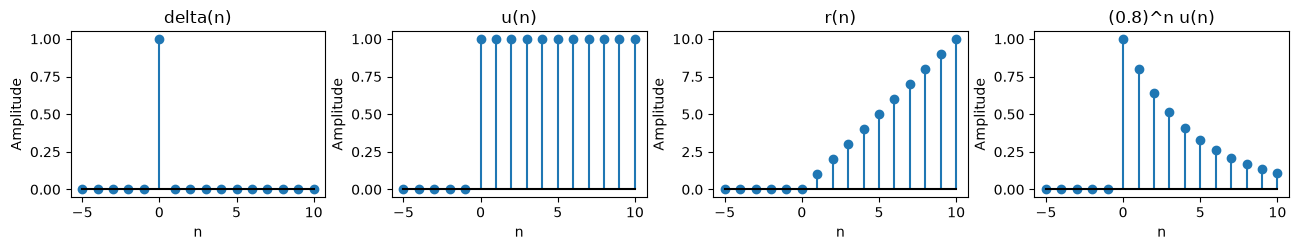

In [3]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)      # unit impulse
step = (n >= 0).astype(float)       # unit step
ramp = n * step                     # unit ramp
expo = (0.8 ** n) * step            # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["delta(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

Task 1.2

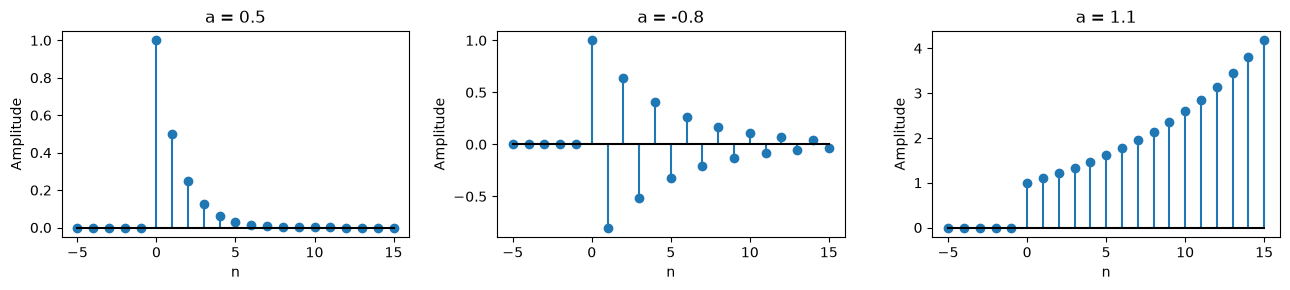

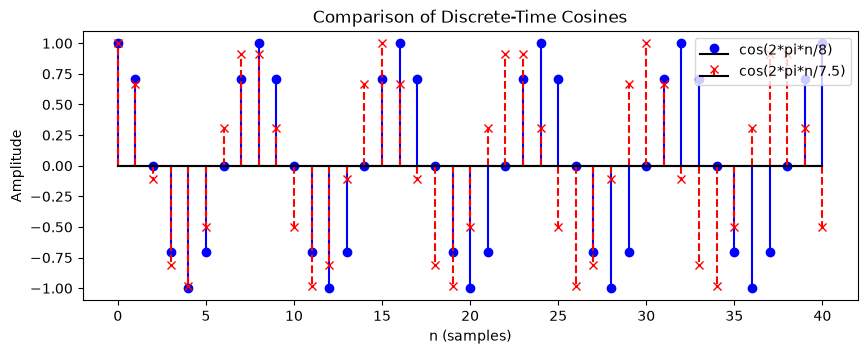

In [4]:
n_exp = np.arange(-5, 16)
step_exp = (n_exp >= 0).astype(float)
alphas = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, a in zip(axes, alphas):
    sig = (a ** n_exp) * step_exp
    ax.stem(n_exp, sig, basefmt="k-")
    ax.set_title(f"a = {a}")
    ax.set_xlabel("n")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

n_cos = np.arange(0, 41)
c1 = np.cos(2 * np.pi * n_cos / 8)
c2 = np.cos(2 * np.pi * n_cos / 7.5)

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.stem(n_cos, c1, linefmt="b-", markerfmt="bo", basefmt="k-", label="cos(2*pi*n/8)")
ax.stem(n_cos, c2, linefmt="r--", markerfmt="rx", basefmt="k-", label="cos(2*pi*n/7.5)")
ax.set_title("Comparison of Discrete-Time Cosines")
ax.set_xlabel("n (samples)")
ax.set_ylabel("Amplitude")
ax.legend()
plt.show()

Task 1.3

In [5]:
import os
from scipy.io import wavfile
from IPython.display import Audio

fname = "my_voice.wav"
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:
        x = x.mean(axis=1)  # hubadili stereo kuwa mono kama ina njia zaidi ya moja
    x = x.astype(float) / np.max(np.abs(x))
    print(f"Sampling rate: {fs} Hz | Duration: {len(x)/fs:.2f} s | Samples: {len(x)}")
    display(Audio(x, rate=fs))
else:
    print(f"File '{fname}' not found in {os.getcwd()}")

ValueError: File format b'\xff\xfb\x90\xc4' not understood. Only 'RIFF', 'RIFX', and 'RF64' supported.

In [6]:
import librosa
import soundfile as sf
from IPython.display import Audio
import numpy as np

fname = "my_voice.wav"

# 1. Soma sauti (inafanya kazi hata kama chanzo kilikuwa MP3)
x, fs = librosa.load(fname, sr=None, mono=True)

# 2. Hifadhi upya kama WAV halisi (PCM 16-bit)
sf.write("my_voice_clean.wav", x, fs, subtype="PCM_16")

# 3. Panga amplitude ndani ya [-1, 1] na kuonyesha matokeo
x_norm = x / np.max(np.abs(x))
print(f"Sampling rate: {fs} Hz | Duration: {len(x)/fs:.2f} s | Samples: {len(x)}")
display(Audio(x_norm, rate=fs))

Sampling rate: 44100 Hz | Duration: 3.87 s | Samples: 170496
